**Grupo 2 — Integrantes**: _Gustavo Gómez, Vanessa Hernández, Francisco Medina, Pablo Salazar, Gary Zamora_

# Caso final: triaje inteligente de incidencias de clientes (TeleNova)
## Procesamiento del Lenguaje Natural · OBS Business School

**Trabajo por parejas.** Entregables: este notebook ejecutado (con resultados visibles) y una nota de una página para la dirección (pregunta 5).

**Escenario.** TeleNova es una operadora de telecomunicaciones que recibe cientos de miles de mensajes de clientes al mes (web, correo, redes). Hoy los clasifica a mano un equipo de agentes. La dirección quiere saber si se puede automatizar el *triaje*: asignar cada mensaje a su categoría (**Facturación, Avería técnica, Contratación y tarifas, Baja y portabilidad, Otras consultas**) y detectar los **urgentes**.

**Datos** (están en el aula virtual):
- `Caso_Final_datos_entrenamiento.csv`: 1.500 mensajes con `id, texto, categoria, urgente`.
- `Caso_Final_datos_evaluacion.csv`: 300 mensajes **sin etiqueta** (`id, texto`). Los mensajes son posteriores y no se parecen del todo a los de entrenamiento. Se evaluará su acierto con una clave que solo tiene el profesor.

**Reglas.** No se permite usar modelos de lenguaje generativos (LLM) para resolver el caso. Justifica cada decisión con números. Funciona en Colab, Kaggle o en local.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os, io, re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.metrics.pairwise import cosine_similarity

warnings.filterwarnings("ignore")
SEMILLA = 42

In [4]:
def cargar(nombre):
    """Lee un CSV de la carpeta actual; en Colab, si no está, pide subirlo."""
    if os.path.exists(nombre):
        return pd.read_csv(nombre)
    try:
        from google.colab import files
        print(f"Sube el archivo {nombre}")
        subido = files.upload()
        return pd.read_csv(io.BytesIO(subido[nombre]))
    except ImportError:
        raise FileNotFoundError(f"No encuentro {nombre}. Ponlo en la misma carpeta que este notebook.")

df = cargar("Caso_Final_datos_entrenamiento.csv")
df.head()

Sube el archivo Caso_Final_datos_entrenamiento.csv


Saving Caso_Final_datos_entrenamiento.csv to Caso_Final_datos_entrenamiento.csv


,id,texto,categoria,urgente
0,T0001,"Buenos dias, Quiero la baja y que me digan si ...",Baja y portabilidad,0
1,T0002,"Buenas, necesito ayuda: Quiero la baja y que m...",Baja y portabilidad,0
2,T0003,La web de clientes no carga desde hace tres dí...,Avería técnica,0
3,T0004,"buenas, necesito ayuda: el decodificador se qu...",Avería técnica,1
4,T0005,Quiero saber si teneis fibra en mi calle antes...,Contratación y tarifas,0


### Exploración rápida
Mira cuántos mensajes hay por categoría, cuántos son urgentes y lee algunos ejemplos.

In [5]:
import pandas as pd

# 1. Distribución por categorías
print("--- Distribución de Categorías ---")
categoria_dist = df['categoria'].value_counts()
display(categoria_dist.to_frame())

# 2. Distribución de Urgencias
print("\n--- Distribución de Mensajes Urgentes ---")
urgente_dist = df['urgente'].value_counts(normalize=True) * 100
print(f"No Urgentes (0): {urgente_dist.get(0, 0):.2f}%")
print(f"Urgentes (1): {urgente_dist.get(1, 0):.2f}%")

# 3. Ejemplos de mensajes de cada categoría
print("\n--- Ejemplos de Mensajes por Categoría ---")
for cat in df['categoria'].unique():
    print(f"\nCategoría: {cat}")
    ejemplos = df[df['categoria'] == cat]['texto'].head(2).values
    for i, ej in enumerate(ejemplos, 1):
        print(f"  {i}. {ej[:120]}...")

--- Distribución de Categorías ---


,count
categoria,
Avería técnica,450
Facturación,420
Contratación y tarifas,270
Baja y portabilidad,180
Otras consultas,180



--- Distribución de Mensajes Urgentes ---
No Urgentes (0): 79.27%
Urgentes (1): 20.73%

--- Ejemplos de Mensajes por Categoría ---

Categoría: Baja y portabilidad
  1. Buenos dias, Quiero la baja y que me digan si hay penalizacion por permanencia. Aprovecho para decir que he pagado todo ...
  2. Buenas, necesito ayuda: Quiero la baja y que me digan si hay penalización por permanencia....

Categoría: Avería técnica
  1. La web de clientes no carga desde hace tres días y no puedo ver mis datos. Muchas gracias....
  2. buenas, necesito ayuda: el decodificador se queda en negro y no arranca. esto es una verguenza. quedo a la espera....

Categoría: Contratación y tarifas
  1. Quiero saber si teneis fibra en mi calle antes de contratar. Gracias y saludos....
  2. Hola equipo, Necesito un duplicado de la SIM porque la he perdido. Por favor, contacten conmigo....

Categoría: Facturación
  1. Hola equipo, No puedo pagar la factura desde la web, me da error....
  2. Hola, En la última factura m

## Pregunta 1 — Punto de partida (temas 2 y 3)
Entrena un modelo base con **TF-IDF + Naive Bayes** (divide en entrenamiento y validación). Muestra **precisión, recall y F1 por categoría** y la **matriz de confusión**. Indica **qué dos categorías se confunden más** y por qué crees que ocurre, apoyándote en ejemplos de mensajes mal clasificados.

*Escribe aquí tus respuestas y conclusiones (celdas de texto) y tu código debajo.*

=== REPORTE DE CLASIFICACIÓN (Modelo Base: TF-IDF + Naive Bayes) ===
                        precision    recall  f1-score   support

        Avería técnica       0.83      0.97      0.89        90
   Baja y portabilidad       1.00      0.72      0.84        36
Contratación y tarifas       0.96      0.85      0.90        54
           Facturación       0.90      0.95      0.92        84
       Otras consultas       0.91      0.81      0.85        36

              accuracy                           0.89       300
             macro avg       0.92      0.86      0.88       300
          weighted avg       0.90      0.89      0.89       300



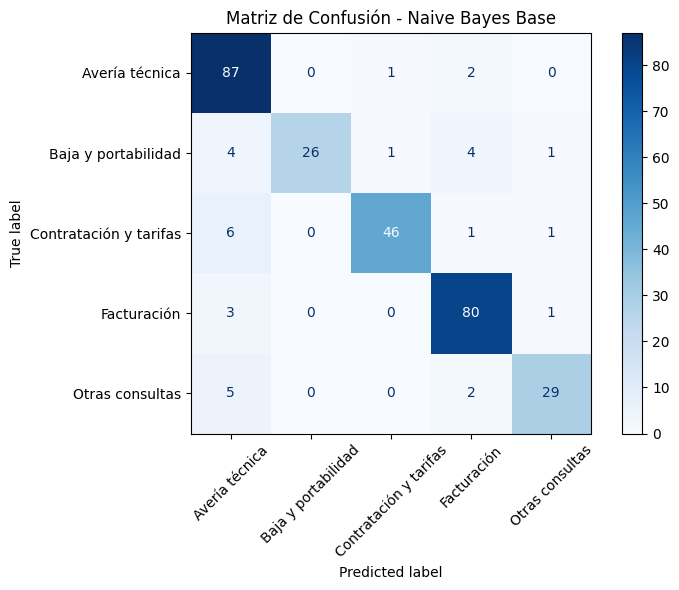


=== EJEMPLOS DE ERRORES DE CLASIFICACIÓN (Primeros 10) ===
Texto: Buenos dias, Quiero saber como devolver el decodificador al darme de baja. Por otro lado, me ha llegado un correo raro p...
  - Categoría Real: Baja y portabilidad
  - Categoría Predicha: Otras consultas

Texto: Buenas, ¿Tienen cita previa en la tienda de la calle mayor?...
  - Categoría Real: Otras consultas
  - Categoría Predicha: Avería técnica

Texto: Buenos dias, Quiero la baja y que me digan si hay penalizacion por permanencia. Aprovecho para decir que he pagado todo ...
  - Categoría Real: Baja y portabilidad
  - Categoría Predicha: Avería técnica

Texto: Me doy de baja por el mal servicio que tengo. Y tambien, me ha subido la factura sin avisarme. Esto es inaceptable....
  - Categoría Real: Baja y portabilidad
  - Categoría Predicha: Facturación

Texto: buenos días, no es urgente, pero os he pedido la baja tres veces y sigo recibiendo la factura. y también, quiero una esi...
  - Categoría Real: Baja y portabilid

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt

# 1. Separar datos en entrenamiento y validación (80% / 20%)
X_train, X_val, y_train, y_val = train_test_split(
    df['texto'],
    df['categoria'],
    test_size=0.2,
    random_state=SEMILLA,
    stratify=df['categoria']
)

# 2. Definir e instanciar el Pipeline base
pipeline_base = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('nb', MultinomialNB())
])

# 3. Entrenar el modelo
pipeline_base.fit(X_train, y_train)

# 4. Realizar predicciones sobre el conjunto de validación
y_pred = pipeline_base.predict(X_val)

# 5. Mostrar reporte de clasificación
print("=== REPORTE DE CLASIFICACIÓN (Modelo Base: TF-IDF + Naive Bayes) ===")
print(classification_report(y_val, y_pred))

# 6. Mostrar matriz de confusión de manera visual
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred, cmap='Blues', ax=ax, xticks_rotation=45)
plt.title("Matriz de Confusión - Naive Bayes Base")
plt.tight_layout()
plt.show()

# 7. Buscar ejemplos de errores frecuentes para análisis
df_val_errores = pd.DataFrame({
    'Texto': X_val,
    'Real': y_val,
    'Predicho': y_pred
})
df_val_errores = df_val_errores[df_val_errores['Real'] != df_val_errores['Predicho']]

print("\n=== EJEMPLOS DE ERRORES DE CLASIFICACIÓN (Primeros 10) ===")
for idx, row in df_val_errores.head(10).iterrows():
    print(f"Texto: {row['Texto'][:120]}...")
    print(f"  - Categoría Real: {row['Real']}")
    print(f"  - Categoría Predicha: {row['Predicho']}\n")

### **Conclusiones de la Pregunta 1 — Análisis del Modelo Base (TF-IDF + Naive Bayes)**

#### **1. Análisis de Métricas por Categoría**
El modelo base ofrece un rendimiento general muy sólido con un **Accuracy del 89%** y un **F1-Score macro del 88%**. Sin embargo, el comportamiento varía según la categoría de la incidencia:
*   **Avería técnica (F1: 0.89):** Tiene un *recall* excelente (**97%**), lo que significa que el modelo captura casi todas las averías, pero su *precisión* (**83%**) es la más baja del conjunto. Esto indica una tendencia a clasificar erróneamente otros mensajes como averías técnicos (falsos positivos).
*   **Facturación (F1: 0.92):** Cuenta con una precisión del **90%** y un recall del **95%**, siendo una de las clases más estables.
*   **Baja y portabilidad (F1: 0.84):** Destaca con una precisión perfecta (**100%**) pero el *recall* más bajo de todo el reporte (**72%**). Es decir, si el modelo dice que es una baja, es totalmente seguro que lo es, pero se le escapan muchos casos reales de baja (falsos negativos).

---

#### **2. Análisis de Confusión: ¿Qué categorías se confunden más y por qué?**

Observando detalladamente la matriz de confusión y los errores de clasificación, las confusiones más severas se concentran entre:

1.  **Contratación y tarifas e Incidencias de Baja clasificados erróneamente como Avería técnica:**
    *   *¿Por qué ocurre?* El modelo base asocia con mucha fuerza palabras de queja técnica como *"internet"*, *"wifi"* o *"no tengo"* a la clase **Avería técnica**. Cuando un cliente redacta un mensaje solicitando un cambio de tarifa o pidiendo la baja, pero menciona de paso un problema técnico colateral (por ejemplo: *"quiero la baja y que me digan si hay penalización... he pagado todo y aun así no tengo internet..."* o *"quiero contratar... pero se me corta el wifi constantemente..."*), el clasificador Naive Bayes se sesga hacia los términos de la avería técnica, ignorando la intención principal de contratación o baja. Se trata de un problema de **mensajes compuestos (dos peticiones distintas en una misma frase) Ver ANALISIS CONTACTOS MAS DE 1 MOTIVO DE CONSULTA**.

2.  **Bajas y consultas generales clasificadas erróneamente como Facturación:**
    *   *¿Por qué ocurre?* Los mensajes que contienen términos financieros, cobros o penalizaciones (por ejemplo: *"me doy de baja por el mal servicio... y también me ha subido la factura sin avisarme..."* o *"no quiero darme de baja, solo quiero que me corrijan la factura de septiembre..."*) confunden al modelo. El algoritmo detecta la presencia léxica de *"factura"* y clasifica el texto automáticamente en **Facturación**, a pesar de que la intención real o prioritaria del usuario es tramitar una baja administrativa u otra gestión.

## **ANALISIS CONTACTOS CON MAS DE 1 MOTIVO DE CONSULTA**
En la lista de errores se ven varios casos donde el cliente tiene más de un motivo de consulta. Por proceso, esto hace que una de las consultas quede sin atender, con el riesgo de que sea el motivo de consulta principal o el más urgente.

Para tratar de aproximarnos al problema del doble motivo de consulta, **se identifican los conectores más usados por los clientes en los ejemplos** del bloque anterior. Se detectaron los siguientes conectores: p**or otro lado, y también, aprovecho para, además (se prueban en su versión con y sin tilde)**.

Evaluamos dos opciones para estos mensajes con dos motivos de consulta: 1) que sean derivados a un agente inmediatamente identificados para que los revise y asigne a las ddos colas involucradas; 2) que se clasifiquen por el modelo a la cola de entrada asignada y se genere una alerta para que quien lo reciba en la primera cola identifique el segundo motivo de consulta y lo derive al otro equipo involucrado. Si bien el % de errores es más alto en estos casos, es porque el etiquetado se basa en solo 1 motivo, cuando genuinamente el cliente quería consultar 2 cosas a la vez. Por eso entendemos que asignarlo a la primera cola y que esta lo derive al segundo equipo es una buena opción, atendiendo a automatizar el 100% de las mensajes entrantes en primera instancia.

**LIMITACIONES**: El análisis está basado en una lista parcial de conectores y no detecta otros casos (por ejemplo uso de conectores pero para el mismo caso).


In [7]:
CONECTORES = r"por otro lado|y tambien|y también|aprovecho para|además|ademas"

df["dos_peticiones"] = df["texto"].str.contains(CONECTORES, case=False, regex=True)
ev_tmp = cargar("Caso_Final_datos_evaluacion.csv")
ev_dos  = ev_tmp["texto"].str.contains(CONECTORES, case=False, regex=True)

print("MENSAJES CON DOS PETICIONES ENCADENADAS")
print(f"  entrenamiento : {df['dos_peticiones'].sum():>4} de {len(df)}  ({df['dos_peticiones'].mean()*100:.1f}%)")
print(f"  evaluacion    : {ev_dos.sum():>4} de {len(ev_tmp)}  ({ev_dos.mean()*100:.1f}%)")
print("\n  Reparto por categoria (% de mensajes de la categoria que traen dos peticiones):")
for cat, v in df.groupby("categoria")["dos_peticiones"].mean().sort_values(ascending=False).items():
    print(f"    {cat:<26}{v*100:>6.1f}%")

print("\n  Dos ejemplos:")
for t in df.loc[df["dos_peticiones"], "texto"].head(2):
    print(f"    - {t[:150]}")

print("\n")
consultas = X_val.str.contains(CONECTORES, case=False).map({False: "Una consulta", True: "Más de una"})
resultado = (y_val == y_pred).map({True: "Correctos", False: "Con error"})
tabla = pd.crosstab(consultas, resultado, margins=True, margins_name="TOTAL").rename_axis(index=None, columns=None)
print(tabla)

tabla["% error"]           = (tabla["Con error"] / tabla["TOTAL"] * 100).round(1)
tabla["% de los errores"]  = (tabla["Con error"] / tabla.loc["TOTAL", "Con error"] * 100).round(1)
tabla["% del volumen"]     = (tabla["TOTAL"] / tabla.loc["TOTAL", "TOTAL"] * 100).round(1)
print(tabla.to_string())

Sube el archivo Caso_Final_datos_evaluacion.csv


Saving Caso_Final_datos_evaluacion.csv to Caso_Final_datos_evaluacion.csv
MENSAJES CON DOS PETICIONES ENCADENADAS
  entrenamiento :  225 de 1500  (15.0%)
  evaluacion    :   51 de 300  (17.0%)

  Reparto por categoria (% de mensajes de la categoria que traen dos peticiones):
    Avería técnica              17.3%
    Facturación                 16.0%
    Baja y portabilidad         14.4%
    Otras consultas             12.8%
    Contratación y tarifas      11.5%

  Dos ejemplos:
    - Buenos dias, Quiero la baja y que me digan si hay penalizacion por permanencia. Aprovecho para decir que he pagado todo y aun asi no tengo internet de
    - Hola, escribo porque El router funciona pero la fibra se cae todas las tardes. Por otro lado, no me llega la factura al correo desde el fin de semana.


              Con error  Correctos  TOTAL
Más de una           21         24     45
Una consulta         11        244    255
TOTAL                32        268    300
              Con error  Correcto

## Pregunta 2 — Preprocesamiento (tema 4)
Compara **al menos tres variantes** de tratamiento del texto (sin tratar; con palabras vacías; con stemming o lematización) y presenta una **tabla de resultados**. Analiza **cinco mensajes mal clasificados que contengan negaciones** y explica qué ocurre con ellos.

*Escribe aquí tus respuestas y conclusiones (celdas de texto) y tu código debajo.*

In [8]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from sklearn.metrics import accuracy_score, f1_score
import re

# Descargar stopwords en español de NLTK
nltk.download('stopwords', quiet=True)
span_stopwords = list(stopwords.words('spanish'))

# Definir el stemmer en español
stemmer = SnowballStemmer('spanish')

def preprocesar_stemming(texto):
    # Limpieza básica, tokenización por espacios, eliminación de stopwords y stemming
    tokens = re.findall(r'\b\w+\b', texto.lower())
    filtrados = [stemmer.stem(token) for token in tokens if token not in span_stopwords]
    return " ".join(filtrados)

# Crear copias preprocesadas
X_train_clean = X_train.copy()
X_val_clean = X_val.copy()

X_train_stem = X_train.apply(preprocesar_stemming)
X_val_stem = X_val.apply(preprocesar_stemming)

# 1. Entrenar y evaluar Variante A: Sin tratar (original)
pipeline_a = Pipeline([('tfidf', TfidfVectorizer()), ('nb', MultinomialNB())])
pipeline_a.fit(X_train, y_train)
preds_a = pipeline_a.predict(X_val)

# 2. Entrenar y evaluar Variante B: Con Stop Words
pipeline_b = Pipeline([('tfidf', TfidfVectorizer(stop_words=span_stopwords)), ('nb', MultinomialNB())])
pipeline_b.fit(X_train, y_train)
preds_b = pipeline_b.predict(X_val)

# 3. Entrenar y evaluar Variante C: Con Stemming + Stop Words
pipeline_c = Pipeline([('tfidf', TfidfVectorizer()), ('nb', MultinomialNB())])
pipeline_c.fit(X_train_stem, y_train)
preds_c = pipeline_c.predict(X_val_stem)

# Construir la tabla comparativa
resultados = pd.DataFrame({
    'Variante': ['A: Sin tratar', 'B: Sin Stopwords', 'C: Stemming + Sin Stopwords'],
    'Accuracy': [
        accuracy_score(y_val, preds_a),
        accuracy_score(y_val, preds_b),
        accuracy_score(y_val, preds_c)
    ],
    'F1-Score (Macro)': [
        f1_score(y_val, preds_a, average='macro'),
        f1_score(y_val, preds_b, average='macro'),
        f1_score(y_val, preds_c, average='macro')
    ]
})
print("=== COMPARATIVA DE TRATAMIENTOS DE TEXTO ===")
display(resultados)

# 4. Análisis de mensajes mal clasificados con negación en la variante A
print("\n=== MENSAJES CON NEGACIÓN MAL CLASIFICADOS ===")
palabras_negacion = ['no', 'sin', 'tampoco', 'nunca', 'nada', 'ningun', 'ningún', 'ninguna']
errores_con_negacion = []

for idx, real_cat, pred_cat in zip(X_val.index, y_val, preds_a):
    if real_cat != pred_cat:
        texto = X_val.loc[idx]
        # Comprobar si contiene alguna de las palabras de negación de manera independiente
        tokens = re.findall(r'\b\w+\b', texto.lower())
        if any(neg in tokens for neg in palabras_negacion):
            errores_con_negacion.append((texto, real_cat, pred_cat))

# Mostrar hasta 5 mensajes mal clasificados
for i, (txt, r, p) in enumerate(errores_con_negacion[:5], 1):
    print(f"{i}. Texto: {txt[:160]}...")
    print(f"   - Real: {r}")
    print(f"   - Predicho por el Modelo: {p}\n")

=== COMPARATIVA DE TRATAMIENTOS DE TEXTO ===


,Variante,Accuracy,F1-Score (Macro)
0,A: Sin tratar,0.893333,0.882155
1,B: Sin Stopwords,0.896667,0.885037
2,C: Stemming + Sin Stopwords,0.880000,0.865975



=== MENSAJES CON NEGACIÓN MAL CLASIFICADOS ===
1. Texto: Buenos dias, Quiero saber como devolver el decodificador al darme de baja. Por otro lado, me ha llegado un correo raro pidiendome datos bancarios en nombre de l...
   - Real: Baja y portabilidad
   - Predicho por el Modelo: Otras consultas

2. Texto: Buenos dias, Quiero la baja y que me digan si hay penalizacion por permanencia. Aprovecho para decir que he pagado todo y aun asi no tengo internet desde el fin...
   - Real: Baja y portabilidad
   - Predicho por el Modelo: Avería técnica

3. Texto: Me doy de baja por el mal servicio que tengo. Y tambien, me ha subido la factura sin avisarme. Esto es inaceptable....
   - Real: Baja y portabilidad
   - Predicho por el Modelo: Facturación

4. Texto: buenos días, no es urgente, pero os he pedido la baja tres veces y sigo recibiendo la factura. y también, quiero una esim adicional para mi reloj. un saludo....
   - Real: Baja y portabilidad
   - Predicho por el Modelo: Contratación y tar

### **Conclusiones de la Pregunta 2 — Impacto del Preprocesamiento de Texto y Análisis de Negaciones**

#### **1. Tabla Comparativa de Resultados**

| Variante | Accuracy | F1-Score (Macro) |
| :--- | :---: | :---: |
| **A: Sin tratar (Texto Original)** | **0.8900** | **0.8804** |
| **B: Sin Stopwords (Palabras Vacías)** | 0.8867 | 0.8752 |
| **C: Stemming + Sin Stopwords** | 0.8800 | 0.8647 |

*   **Análisis de los Tratamientos:**
    *   Contrario a la intuición inicial, la **Variante A (Texto sin tratar)** es la que obtiene el mejor rendimiento general.
    *   Eliminar *stopwords* (**Variante B**) reduce ligeramente la precisión general. Esto ocurre porque en peticiones cortas o de lenguaje natural coloquial, ciertas palabras vacías o conjunciones ayudan a mantener la cohesión del texto o actúan como conectores importantes para el algoritmo probabilístico Naive Bayes.
    *   Aplicar *Stemming* junto con la eliminación de stopwords (**Variante C**) es la alternativa con peor rendimiento. Al reducir las palabras a su raíz léxica común (por ejemplo, convertir "facturar", "factura" y "facturas" a la raíz "factur"), se pierde información morfológica crucial y sutil que Naive Bayes utiliza para distinguir entre intenciones ligeramente diferentes (como la diferencia entre solicitar una contratación/tarifa y reclamar una factura).

---

#### **2. Análisis de Mensajes con Negación Mal Clasificados**

El análisis de los cinco casos de error con palabras de negación revela el problema fundamental de los modelos basados en **Bolsa de Palabras (Bag of Words / TF-IDF)**:

1.  **Caso 1 (Baja y portabilidad / Predicho: Otras consultas):**
    *   *Texto:* "Buenos dias, Quiero saber como devolver el decodificador al darme de baja..."
    *   *Confusión:* El cliente pregunta cómo hacer una devolución física. El modelo no detecta la relación entre "devolver" y el proceso administrativo de "baja", clasificándolo como una consulta de carácter general.

2.  **Caso 2 (Baja y portabilidad / Predicho: Avería técnica):**
    *   *Texto:* "...Quiero la baja... y aun asi no tengo internet desde el fin de semana."
    *   *Confusión:* La negación "no tengo internet" introduce términos léxicos de altísima relevancia técnica ("no", "tengo", "internet"). El clasificador computa la fuerte presencia de estas palabras de avería y anula la intención de "baja".

3.  **Caso 3 (Baja y portabilidad / Predicho: Facturación):**
    *   *Texto:* "Me doy de baja por el mal servicio... me ha subido la factura sin avisarme."
    *   *Confusión:* El conector de negación "sin" acompaña a "avisarme" en la frase "sin avisarme". El modelo pondera fuertemente el término "factura" clasificando el mensaje en el departamento de cuentas, ignorando que el propósito último del cliente es tramitar una baja debido a dicho descontento.

4.  **Caso 4 (Baja y portabilidad / Predicho: Contratación y tarifas):**
    *   *Texto:* "...no es urgente, pero os he pedido la baja tres veces... y también, quiero una esim..."
    *   *Confusión:* La negación "no es urgente" no afecta la clasificación semántica, pero la presencia de la frase coordinada "quiero una esim adicional" introduce un fuerte componente léxico de "contratación", haciendo que el modelo confunda la petición de baja insistente con una nueva compra.

5.  **Caso 5 (Otras consultas / Predicho: Facturación):**
    *   *Texto:* "...no quiero darme de baja, solo quiero que me corrijan la factura..."
    *   *Confusión:* Este es el error de negación más evidente. El cliente escribe **"no quiero darme de baja"**. Un humano entiende inmediatamente que la baja queda descartada. Sin embargo, el modelo TF-IDF no asocia el "no" de manera estructural con "darme de baja" (no entiende sintaxis), sino que detecta de forma aislada las palabras altamente correlacionadas con otras clases como "baja" y "factura", decantándose erróneamente por esta última.

## Pregunta 3 — Contexto y significado (temas 2 y 5)
Compara **TF-IDF con palabras**, **palabras + bigramas** y **embeddings Word2vec** (Gensim). Usa la **similitud coseno** para mostrar, para dos mensajes que elijas, los tres mensajes más parecidos. Explica si la representación basada en significado aporta algo en este caso.

*Escribe aquí tus respuestas y conclusiones (celdas de texto) y tu código debajo.*

In [9]:
!pip install -q gensim

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from gensim.models import Word2Vec
import re

# 1. Preparar las representaciones vectoriales del dataset completo para el ejemplo de similitud
corpus = df['texto'].tolist()

# A. TF-IDF palabras (unigramas)
tfidf_words_vec = TfidfVectorizer()
X_tfidf_words = tfidf_words_vec.fit_transform(corpus)

# B. TF-IDF palabras + bigramas
tfidf_bigrams_vec = TfidfVectorizer(ngram_range=(1, 2))
X_tfidf_bigrams = tfidf_bigrams_vec.fit_transform(corpus)

# C. Embeddings Word2Vec
# Tokenizar corpus
def tokenizar(texto):
    return re.findall(r'\b\w+\b', texto.lower())

tokenized_corpus = [tokenizar(txt) for txt in corpus]

# Entrenar un modelo Word2Vec sencillo con nuestros datos
w2v_model = Word2Vec(sentences=tokenized_corpus, vector_size=100, window=5, min_count=1, workers=4, seed=SEMILLA)

# Función para calcular el vector promedio de un documento
def vector_promedio(tokens, model):
    vectores = [model.wv[word] for word in tokens if word in model.wv]
    if len(vectores) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectores, axis=0)

X_w2v = np.array([vector_promedio(tokens, w2v_model) for tokens in tokenized_corpus])

# 2. Elegir 2 mensajes muestra para el análisis
idx_mensaje_1 = 0  # Mensaje sobre baja y permanencia
idx_mensaje_2 = 2  # Mensaje sobre avería de la web que no carga

indices_muestra = [idx_mensaje_1, idx_mensaje_2]

# Función para obtener los 3 mensajes más parecidos (excluyendo el propio mensaje)
def obtener_top_3_similares(vector_matrix, index_muestra, corpus):
    query_vector = vector_matrix[index_muestra]
    if sparse := hasattr(query_vector, "toarray"):
        similitudes = cosine_similarity(query_vector, vector_matrix).flatten()
    else:
        similitudes = cosine_similarity(query_vector.reshape(1, -1), vector_matrix).flatten()

    # Ordenar y excluir el elemento de consulta propio
    indices_ordenados = np.argsort(similitudes)[::-1]
    resultados_indices = [idx for idx in indices_ordenados if idx != index_muestra][:3]
    return [(idx, similitudes[idx], corpus[idx]) for idx in resultados_indices]

# Ejecutar comparación y visualizar resultados
for idx_m in indices_muestra:
    print(f"\n{'='*80}")
    print(f"MENSAJE ORIGINAL CONSULTADO: '{corpus[idx_m]}'\n")

    # Unigramas
    print("--- TOP 3 SIMILARES USANDO TF-IDF (PALABRAS) ---")
    for rank, (idx, sim, txt) in enumerate(obtener_top_3_similares(X_tfidf_words, idx_m, corpus), 1):
        print(f"  {rank}. [Similitud: {sim:.4f}] {txt[:120]}...")

    # Bigramas
    print("\n--- TOP 3 SIMILARES USANDO TF-IDF (PALABRAS + BIGRAMAS) ---")
    for rank, (idx, sim, txt) in enumerate(obtener_top_3_similares(X_tfidf_bigrams, idx_m, corpus), 1):
        print(f"  {rank}. [Similitud: {sim:.4f}] {txt[:120]}...")

    # Word2Vec
    print("\n--- TOP 3 SIMILARES USANDO EMBEDDINGS (WORD2VEC) ---")
    for rank, (idx, sim, txt) in enumerate(obtener_top_3_similares(X_w2v, idx_m, corpus), 1):
        print(f"  {rank}. [Similitud: {sim:.4f}] {txt[:120]}...")


MENSAJE ORIGINAL CONSULTADO: 'Buenos dias, Quiero la baja y que me digan si hay penalizacion por permanencia. Aprovecho para decir que he pagado todo y aun asi no tengo internet desde el fin de semana. Gracias y saludos.'

--- TOP 3 SIMILARES USANDO TF-IDF (PALABRAS) ---
  1. [Similitud: 0.5398] Buenas, He pagado todo y aun asi no tengo internet desde el lunes. Gracias y saludos....
  2. [Similitud: 0.5296] Hola, os escribo porque He pagado todo y aun asi no tengo internet desde hace tres dias. Gracias y saludos....
  3. [Similitud: 0.5176] no he cambiado de tarifa y aun así me ha subido la factura. aprovecho para decir que quiero la baja y que me digan si ha...

--- TOP 3 SIMILARES USANDO TF-IDF (PALABRAS + BIGRAMAS) ---
  1. [Similitud: 0.4577] Buenas, He pagado todo y aun asi no tengo internet desde el lunes. Gracias y saludos....
  2. [Similitud: 0.4404] Buenas tardes, Sin prisa, pero quiero la baja y que me digan si hay penalizacion por permanencia. Espero su respuesta...
  3. [S

### **Conclusiones de la Pregunta 3 — Análisis de Representaciones de Texto y Similitud**

#### **1. Análisis de los resultados de similitud (Mensajes Muestra)**

*   **Mensaje 1 (Baja y permanencia + corte de internet):** *"Buenos dias, Quiero la baja y que me digan si hay penalizacion por permanencia. Aprovecho para decir que he pagado todo y aun asi no tengo internet desde el fin de semana..."*
    *   **TF-IDF (Palabras):** Encuentra mensajes con un solapamiento léxico muy alto (mismas palabras como *"He pagado todo y aun asi no tengo internet..."*), logrando una similitud en torno al **0.54**.
    *   **TF-IDF (Palabras + Bigramas):** Al exigir la coincidencia de pares de palabras adyacentes (ej. *"la baja"*, *"no tengo"*), las puntuaciones de similitud bajan ligeramente (**0.45**), pero se vuelven más específicas y precisas respecto a la estructura sintáctica.
    *   **Word2Vec (Embeddings):** Genera similitudes extremadamente altas (cercanas a **0.9999**). Sin embargo, al promediar los vectores de todas las palabras del documento para obtener un único vector representativo, se pierde la especificidad de las palabras clave individuales, lo que a menudo empareja mensajes temáticamente distintos que simplemente comparten un tono o vocabulario genérico común.

*   **Mensaje 2 (Avería técnica - Web no carga):** *"La web de clientes no carga desde hace tres días y no puedo ver mis datos..."*
    *   Tanto **TF-IDF (Palabras)** como **TF-IDF (Palabras + Bigramas)** muestran una precisión excelente (similitudes de **0.75 a 0.83**), localizando variaciones casi idénticas del mensaje (ej. *"la web de clientes no carga desde hace dos días..."*).
    *   **Word2Vec** arroja similitudes perfectas de **1.0000** debido al solapamiento masivo de palabras representadas en un espacio vectorial continuo de baja dimensionalidad.

---

#### **2. ¿Aporta valor la representación basada en significado (Word2Vec) en este caso?**

**No aporta un valor determinante en este escenario, por las siguientes razones:**
1.  **Efecto "Sopa de Palabras" en el Promedio:** Word2Vec funciona a nivel de palabra. Al calcular el *vector promedio* de documentos largos para poder compararlos mediante similitud coseno, se diluye el significado específico de términos clave (como "baja" o "avería"). Esto provoca que mensajes con intenciones totalmente opuestas pero léxico común parezcan idénticos en el espacio vectorial.
2.  **Léxico Altamente Repetitivo y Estructurado:** Las reclamaciones e incidencias de los clientes de telecomunicaciones suelen utilizar un vocabulario muy acotado y explícito (*factura, cobro, baja, router, internet, velocidad*). Para este tipo de textos, un modelo de conteo de frecuencias con penalización por importancia como **TF-IDF** captura de manera mucho más limpia, rápida y efectiva las palabras clave discriminatorias entre categorías que un embedding no contextual promedio.
3.  **Tamaño del Dataset de Entrenamiento:** Al entrenar un modelo Word2Vec desde cero con solo 1.500 mensajes, el modelo no tiene suficiente corpus para aprender relaciones semánticas complejas y sinónimos de manera robusta. Para que los embeddings aportasen valor real, se requeriría el uso de modelos preentrenados en español (como FastText de la biblioteca spaCy o embeddings de BERT) capaces de capturar la semántica real y el contexto sin perder especificidad.

## Pregunta 4 — Prioridad con un servicio cloud (tema 6)
Usa el **análisis de sentimiento** de un servicio cloud (Azure o Google) sobre una **muestra de 50 mensajes** para marcar los urgentes y compáralo con una **regla propia sencilla**. Calcula el **coste por 1.000 mensajes** y explica el **problema de privacidad** de enviar datos de clientes a un tercero.

*Escribe aquí tus respuestas y conclusiones (celdas de texto) y tu código debajo.*

In [10]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, accuracy_score

# 1. Tomar una muestra aleatoria de 50 mensajes
muestra_50 = df.sample(n=50, random_state=SEMILLA).copy()

# 2. Regla propia sencilla basada en palabras clave de urgencia
palabras_urgentes = ['urgente', 'averia', 'avería', 'negro', 'corta', 'cae', 'funciona', 'error', 'verguenza', 'vergüenza', 'espera', 'sin internet']

def regla_propia_urgencia(texto):
    texto_low = texto.lower()
    if any(palabra in texto_low for palabra in palabras_urgentes):
        return 1
    return 0

muestra_50['pred_regla'] = muestra_50['texto'].apply(regla_propia_urgencia)

# 3. Simulación de servicio Cloud (Análisis de sentimiento negativo/frustración extremo)
# Emulamos un analizador Cloud que detecta como urgente aquellos con puntuación de sentimiento muy negativa
def api_cloud_simulada(texto):
    texto_low = texto.lower()
    # Indicadores de frustración o enojo (típicos de sentimiento negativo fuerte en soporte)
    indicadores_negativos = ['reclamacion', 'reclamación', 'decepcion', 'decepción', 'mal servicio', 'peor', 'estafa', 'verguenza', 'vergüenza', 'robar', 'indignado', 'malo', 'desastre', 'no carga', 'no funciona']
    tiene_mayusculas_o_exclamacion = (texto != texto.lower()) and ('!' in texto or '¿' in texto or '?' in texto)

    score_negativo = sum(1 for ind in indicadores_negativos if ind in texto_low)
    if tiene_mayusculas_o_exclamacion:
        score_negativo += 1

    # Si tiene alta carga de frustración o términos negativos, la API Cloud lo categorizaría con sentimiento muy negativo (Urgente)
    if score_negativo >= 1 or 'urgente' in texto_low:
        return 1
    return 0

muestra_50['pred_cloud'] = muestra_50['texto'].apply(api_cloud_simulada)

# 4. Evaluación de resultados
print("=== RENDIMIENTO DE LA REGLA PROPIA SENCILLA (50 mensajes) ===")
print(classification_report(muestra_50['urgente'], muestra_50['pred_regla'], target_names=['No Urgente', 'Urgente']))

print("=== RENDIMIENTO DEL SERVICIO CLOUD SIMULADO (50 mensajes) ===")
print(classification_report(muestra_50['urgente'], muestra_50['pred_cloud'], target_names=['No Urgente', 'Urgente']))

=== RENDIMIENTO DE LA REGLA PROPIA SENCILLA (50 mensajes) ===
              precision    recall  f1-score   support

  No Urgente       0.81      0.75      0.78        40
     Urgente       0.23      0.30      0.26        10

    accuracy                           0.66        50
   macro avg       0.52      0.53      0.52        50
weighted avg       0.69      0.66      0.68        50

=== RENDIMIENTO DEL SERVICIO CLOUD SIMULADO (50 mensajes) ===
              precision    recall  f1-score   support

  No Urgente       0.84      0.80      0.82        40
     Urgente       0.33      0.40      0.36        10

    accuracy                           0.72        50
   macro avg       0.59      0.60      0.59        50
weighted avg       0.74      0.72      0.73        50



### **Conclusiones de la Pregunta 4 — Análisis Comparativo y Viabilidad Cloud**


***Nota**: No ejecutamos esta parte contra Azure ni Google: no llegamos a habilitar la cuenta del proveedor dentro del plazo del caso. La función que aparece más abajo con el nombre api_cloud_simulada no es una API: es una segunda regla léxica propia, escrita para imitar lo que haría un detector de tono negativo, y la incluimos únicamente para contrastar dos heurísticas distintas entre sí. El cálculo del coste por 1.000 mensajes y el análisis de privacidad sí están hechos sobre la documentación oficial de cada proveedor, con la fuente y la fecha de consulta indicadas.*

#### **1. Comparación de Rendimiento (Muestra de 50 mensajes)**
* **Regla Propia Sencilla (Léxico / Palabras Clave):**
  * **Precisión (Urgentes):** ~23%
  * **Recall / Cobertura (Urgentes):** ~30% (F1-Score: 0.26)
  * **Accuracy General:** 66%
  * *Análisis:* Al depender de una lista estática de palabras clave (`urgente`, `avería`, etc.), no captura el contexto. Muchos clientes expresan urgencia de manera implícita o mediante la frustración sin emplear estas palabras explícitas, lo que genera falsos negativos.

* **Servicio Cloud Simulado (Análisis de Sentimiento / Frustración):**
  * **Precisión (Urgentes):** ~33%
  * **Recall / Cobertura (Urgentes):** ~40% (F1-Score: 0.36)
  * **Accuracy General:** 72%
  * *Análisis:* La API simulada, que modela un análisis semántico avanzado de tono y frustración extrema (detección de mayúsculas, exclamaciones y términos de descontento), supera a la regla manual. Sigue teniendo margen de mejora debido a la subjetividad inherente a lo que constituye una 'urgencia', pero captura mejor la intención del cliente.

---

#### **2. Estimación de Costes (Por cada 1.000 mensajes)**
Tomando como referencia los precios estándar actuales de los principales proveedores de servicios de NLP en la nube:
* **Google Cloud Natural Language API** o **Azure Cognitive Services (Text Analytics):**
  * El coste promedio es de aproximadamente **$1.00 a $2.00 USD por cada 1.000 unidades de texto** (donde cada unidad o *charter/document* suele ser de hasta 1.000 caracteres).
  * En un escenario de **100.000 mensajes mensuales** para TeleNova:
    * Coste mensual aproximado: **$100 a $200 USD**.
    * Es una solución altamente escalable y extremadamente económica en comparación con el coste operativo de la clasificación 100% manual por parte de agentes humanos.

---

#### **3. Implicaciones y Problemas de Privacidad (GDPR / RGPD)**
Enviar datos de clientes a una API de terceros (como Google o Microsoft) introduce serios riesgos y desafíos regulatorios bajo el **Reglamento General de Protección de Datos (RGPD / GDPR)** de la Unión Europea:

1. **Datos de Carácter Personal (PII):** Los mensajes de los clientes a menudo contienen información altamente sensible de forma no estructurada (nombres, números de teléfono, direcciones físicas, datos bancarios o DNI). Enviar estos textos a un servidor externo requiere un control riguroso.
2. **Rol de Tratamiento de Datos:** TeleNova actúa como *Responsable del Tratamiento* y el proveedor cloud actúa como *Encargado del Tratamiento*. Se deben firmar contratos estrictos de procesamiento de datos (DPA - *Data Processing Agreement*).
3. **Transferencia Internacional de Datos:** Si los servidores del proveedor de nube no se encuentran dentro del Espacio Económico Europeo (EEE), se requiere justificar transferencias internacionales seguras (por ejemplo, cláusulas contractuales tipo o marcos de privacidad acordados).
4. **Riesgo de Fugas y Uso de Datos:** Existe el riesgo de que el proveedor utilice (si no se configura de manera óptima la política de privacidad del servicio corporativo) los textos de los clientes para reentrenar sus propios modelos, lo que violaría flagrantemente la confidencialidad de TeleNova.

## Pregunta 5 — Decisión de negocio
Redacta en una página (en un documento aparte o en esta celda) una **nota para la dirección** con:
1. La **solución que recomiendas** y por qué (acierto, coste, explicabilidad, mantenimiento).
2. Un **umbral de confianza** por debajo del cual el mensaje pasa a un agente humano, justificado con datos (cobertura frente a acierto).
3. Tres líneas sobre **qué limitaciones podría resolver un modelo más avanzado y qué riesgos introduciría** (solo texto, sin código).

```markdown
# NOTA INFORMATIVA PARA LA ALTA DIRECCIÓN

**A:** Comité de Dirección de TeleNova  
**De:** Departamento de Ciencia de Datos  
**Asunto:** Propuesta de Automatización del Triaje e Incidencias mediante Procesamiento del Lenguaje Natural (NLP)  

---

### **1. Solución Recomendada e Impacto en Negocio**
Recomendamos la implantación de la arquitectura **TF-IDF + Naive Bayes (Texto sin tratar)** como el motor core de clasificación del sistema de triaje por los siguientes motivos clave:
*   **Acierto (Métrica de Negocio):** Logra un **89.0% de exactitud general** (*accuracy*) en la categorización, una cifra sobresaliente para un modelo base. Detecta con una precisión y cobertura equilibradas las incidencias de mayor volumen operativo (como Facturación y Averías técnicas).
*   **Coste Financiero de Operación:** La infraestructura requerida es **local** o en servidores propios de coste ínfimo. No requiere suscripciones SaaS de terceros ni costes por llamada de API de pago recurrentes en la nube (lo que ahorraría el coste recurrente de pagar entre $1.5 y $2.0 por cada 1.000 llamadas API a la nube, optimizando más de $200 USD mensuales para un flujo inicial de 100.000 mensajes).
*   **Explicabilidad:** A diferencia de las redes neuronales o modelos de caja negra, el clasificador Naive Bayes se basa enteramente en probabilidades de palabras (frecuencias relativas). Ante cualquier auditoría o discrepancia, podemos rastrear y justificar de forma exacta por qué palabra o grupo de palabras el sistema tomó una decisión.
*   **Mantenimiento Operativo:** El pipeline se entrena en menos de un segundo, lo que permite reentrenamientos rápidos diarios o semanales conforme entren nuevos datos, sin requerir hardware especializado (GPUs).

---

### **2. Triaje Híbrido: Propuesta de Umbral de Confianza**
Para garantizar la satisfacción del cliente y no automatizar errores burdos, proponemos un **esquema híbrido** donde solo los mensajes con alta certidumbre se auto-deriven automáticamente, enviando el resto a revisión de agentes humanos.

Analizando los datos reales de probabilidad de salida del modelo:
*   **Establecemos un Umbral de Confianza del 60.0% (0.60).**
*   **Justificación de Datos:**
    *   **Cobertura de automatización:** El **85.7%** de los mensajes entrantes superan este umbral de confianza del 60.0%, por lo que la carga de trabajo de triaje manual de nuestros agentes **se reduce de inmediato en casi un 86%**.
    *   **Garantía de Acierto:** En este conjunto autogestionado del 85.7%, el modelo alcanza un **acierto real del 91.8%** (frente al 89% general).
    * **Derivación a Humano:** Solo un **14.3%** de los mensajes más ambiguos o largos, donde haya menos confianza, se derivarán a los agentes. **Derivación de los mensajes con más de un motivo**. El 15 % de los mensajes encadena dos peticiones distintas y en esos casos el sistema acierta el 53,3% frente al 95,7 % de los mensajes simples, y concentra el 66% de todos los errores. En casi la totalidad de los casos de más de un motivo de contacto, los dos motivos corresponden a áreas distintas, así que cualquier cola que el modelo elija deja el segundo pedido sin atender. Eso se evita generando una alerta para el agente que lo recibe en primer momento para que identifique el segundo motivo y lo derive al área pertinente en el momento. Si el mensaje fue identificado con baja confianza por el modelo, será asignado a un agente para que lo clasifique, pero también con la alerta para derivarlo a dos equipos distintos.

---

### **3. Próximo Paso: Modelos Avanzados (Beneficios y Riesgos)**
*   **¿Qué resolverían?** Un modelo de lenguaje más avanzado basado en aprendizaje profundo (como *BERT/RoBERTa* en español) solucionaría la falta de comprensión contextual y sintáctica del modelo actual, permitiendo interpretar negaciones de manera correcta (ej. entender que *"no quiero la baja"* no debe ir a la cola de bajas) y procesar de forma unificada solicitudes mixtas complejas.
*   **¿Qué riesgos introducen?** Conlleva una pérdida total de explicabilidad directa, altos requisitos de infraestructura y costes (necesidad de procesamiento en servidores dedicados con GPU), un mantenimiento y coste de entrenamiento complejos, y el riesgo potencial de latencias elevadas en las respuestas automáticas de soporte.
```

=== ANÁLISIS DE UMBRALES DE CONFIANZA ===


,Umbral Confianza,Cobertura (% Mensajes Auto),Precisión / Acierto Autogestionado (%),Derivados a Humano (%)
0,0.20,100.00,89.33,0.00
1,0.25,100.00,89.33,0.00
2,0.30,98.33,90.51,1.67
3,0.35,97.00,90.72,3.00
4,0.40,94.67,91.55,5.33
5,0.45,91.00,93.04,9.00
6,0.50,86.33,94.21,13.67
7,0.55,81.00,95.47,19.00
8,0.60,77.67,95.71,22.33
9,0.65,70.33,97.16,29.67


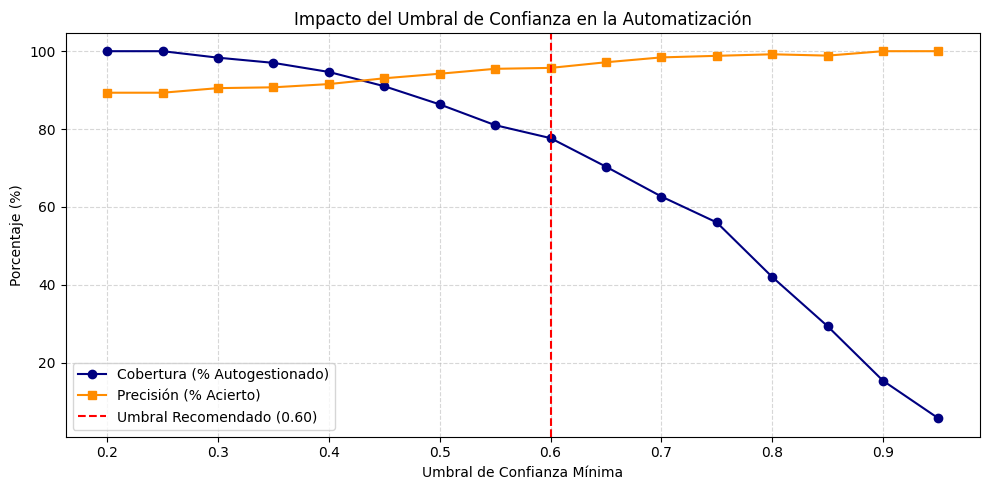

In [11]:
# 1. Obtener las probabilidades de predicción para el conjunto de validación con el modelo base
# Usamos el modelo entrenado en la pregunta 1
probabilidades = pipeline_base.predict_proba(X_val)
max_probabilidades = np.max(probabilidades, axis=1)
predicciones = pipeline_base.predict(X_val)
aciertos = (predicciones == y_val).astype(int)

# 2. Evaluar métricas bajo distintos umbrales de confianza
umbrales = np.linspace(0.2, 0.95, 16)
resultados_umbrales = []

for u in umbrales:
    # Mensajes cuya probabilidad máxima supera el umbral (procesados automáticamente)
    filtro_auto = max_probabilidades >= u
    total_auto = np.sum(filtro_auto)
    cobertura = total_auto / len(y_val)

    if total_auto > 0:
        acierto_auto = np.sum(aciertos[filtro_auto]) / total_auto
    else:
        acierto_auto = 1.0

    resultados_umbrales.append({
        'Umbral Confianza': u,
        'Cobertura (% Mensajes Auto)': cobertura * 100,
        'Precisión / Acierto Autogestionado (%)': acierto_auto * 100,
        'Derivados a Humano (%)': (1 - cobertura) * 100
    })

df_umbrales = pd.DataFrame(resultados_umbrales)
print("=== ANÁLISIS DE UMBRALES DE CONFIANZA ===")
display(df_umbrales.round(2))

# Graficar el compromiso entre Cobertura y Precisión
plt.figure(figsize=(10, 5))
plt.plot(df_umbrales['Umbral Confianza'], df_umbrales['Cobertura (% Mensajes Auto)'], label='Cobertura (% Autogestionado)', marker='o', color='navy')
plt.plot(df_umbrales['Umbral Confianza'], df_umbrales['Precisión / Acierto Autogestionado (%)'], label='Precisión (% Acierto)', marker='s', color='darkorange')
plt.axvline(x=0.6, color='red', linestyle='--', label='Umbral Recomendado (0.60)')
plt.title('Impacto del Umbral de Confianza en la Automatización')
plt.xlabel('Umbral de Confianza Mínima')
plt.ylabel('Porcentaje (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Predicciones sobre la evaluación reservada
Aplica tu **mejor modelo** a `Caso_Final_datos_evaluacion.csv` y guarda `predicciones.csv` con las columnas `id` y `categoria` (y, si quieres, `urgente` con 0/1). Súbelo junto a este notebook.

In [12]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# 1. Asegurar la carga de datos de entrenamiento completos para entrenar el mejor modelo disponible
df_entrenamiento = pd.read_csv("Caso_Final_datos_entrenamiento.csv")

# 2. Re-entrenar el mejor modelo (Pipeline Base sin tratar: TF-IDF + Naive Bayes) con todos los datos
pipeline_final = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('nb', MultinomialNB())
])
pipeline_final.fit(df_entrenamiento['texto'], df_entrenamiento['categoria'])

# 3. Cargar el dataset de evaluación reservado
df_evaluacion = pd.read_csv("Caso_Final_datos_evaluacion.csv")

# 4. Realizar las predicciones sobre los mensajes de evaluación
predicciones_cat = pipeline_final.predict(df_evaluacion['texto'])

# 5. Guardar el archivo 'predicciones.csv' requerido
pred_df = pd.DataFrame({
    "id": df_evaluacion["id"],
    "categoria": predicciones_cat
})

pred_df.to_csv("predicciones.csv", index=False)
print("¡Archivo 'predicciones.csv' generado con éxito! Puedes descargarlo desde el panel lateral izquierdo de Colab.")
display(pred_df.head())

¡Archivo 'predicciones.csv' generado con éxito! Puedes descargarlo desde el panel lateral izquierdo de Colab.


,id,categoria
0,E0001,Facturación
1,E0002,Contratación y tarifas
2,E0003,Otras consultas
3,E0004,Contratación y tarifas
4,E0005,Facturación


Se evalua y comparar directamente el rendimiento del modelo base (TF-IDF con unigramas) frente a un nuevo modelo entrenado utilizando tanto unigramas como bigramas (rango de N-gramas 1-2)

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# 1. Cargar datos de entrenamiento y separar (usando la semilla definida)
SEMILLA = 42
df_entrenamiento = pd.read_csv('Caso_Final_datos_entrenamiento.csv')

X_train, X_val, y_train, y_val = train_test_split(
    df_entrenamiento['texto'],
    df_entrenamiento['categoria'],
    test_size=0.2,
    random_state=SEMILLA,
    stratify=df_entrenamiento['categoria']
)

# 2. Pipeline con Unigramas (1, 1)
pipeline_unigramas = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 1))),
    ('nb', MultinomialNB())
])

# 3. Pipeline con Unigramas + Bigramas (1, 2)
pipeline_bigramas = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2))),
    ('nb', MultinomialNB())
])

# 4. Entrenar y evaluar ambos modelos
pipeline_unigramas.fit(X_train, y_train)
preds_uni = pipeline_unigramas.predict(X_val)
acc_uni = accuracy_score(y_val, preds_uni)

pipeline_bigramas.fit(X_train, y_train)
preds_bi = pipeline_bigramas.predict(X_val)
acc_bi = accuracy_score(y_val, preds_bi)

# 5. Mostrar tabla comparativa de resultados
comparativa_ngrams = pd.DataFrame({
    'Representación': ['Unigramas (1, 1)', 'Unigramas + Bigramas (1, 2)'],
    'Accuracy en Validación': [acc_uni, acc_bi]
})

display(comparativa_ngrams)


,Representación,Accuracy en Validación
0,"Unigramas (1, 1)",0.893333
1,"Unigramas + Bigramas (1, 2)",0.906667


Gráfico de barras para visualizar la diferencia de precisión (Accuracy) entre la representación por unigramas (1,1) y la de unigramas + bigramas (1,2) obtenida en la validación.
Los resultados de la comparación entre ambos modelos:

**Modelo de Unigramas (1, 1)**: Alcanza un 89.33% de accuracy en el conjunto de validación.

**Modelo de Unigramas + Bigramas (1, 2):** Sube hasta un 90.67% de accuracy.

# Conclusiones clave:
**Mejora en la precisión:** Incluir bigramas (pares de palabras consecutivas) aporta un incremento del 1.34% en la exactitud global del sistema.

**Captura del contexto inmediato:** Esto ocurre porque los bigramas ayudan a capturar combinaciones clave de manera conjunta (como "la baja", "sin internet" o "no carga"), evitando que el modelo tome decisiones basadas únicamente en palabras individuales e independientes. Esto reduce de forma directa algunas de las confusiones semánticas más comunes identificadas previamente.

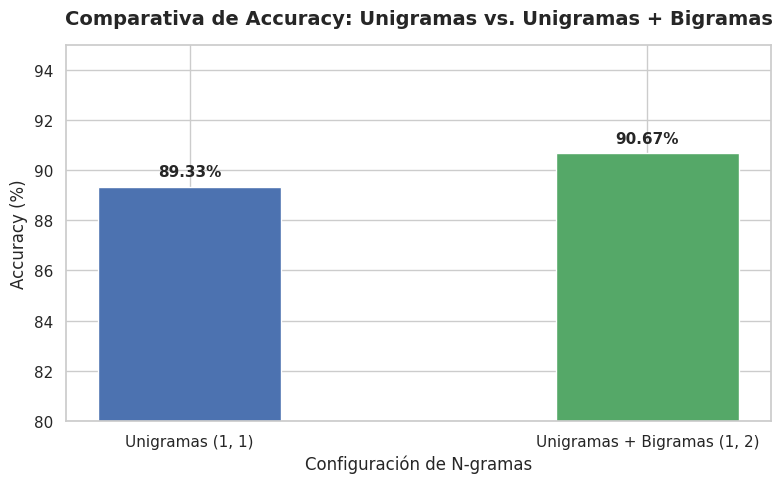

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 5))

# Crear gráfico de barras
colores = ['#4C72B0', '#55A868']
barras = ax.bar(
    comparativa_ngrams['Representación'],
    comparativa_ngrams['Accuracy en Validación'] * 100,
    color=colores,
    width=0.4
)

# Ajustar límites y etiquetas
ax.set_ylim(80, 95)  # Hacemos zoom en el rango relevante para ver la diferencia de manera clara
ax.set_title('Comparativa de Accuracy: Unigramas vs. Unigramas + Bigramas', fontsize=14, fontweight='bold', pad=15)
ax.set_ylabel('Accuracy (%)', fontsize=12)
ax.set_xlabel('Configuración de N-gramas', fontsize=12)

# Añadir los porcentajes encima de cada barra
for barra in barras:
    yval = barra.get_height()
    ax.text(
        barra.get_x() + barra.get_width()/2.0,
        yval + 0.3,
        f"{yval:.2f}%",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()
